# 01 — Територія дослідження

Ноутбук формує територію дослідження для аналізу зв'язку між ВВП та нічним освітленням (NTL):

1. завантажує межі країн Європи з Eurostat GISCO;
2. завантажує річний реальний ВВП з Eurostat (`nama_10_gdp`) за 2012–2025 роки;
3. оцінює повноту рядів ВВП для кожної країни;
4. відбирає країни за критерієм включення та зберігає результати.

**Вихідні файли:**
- `data/economic/eurostat_nama_10_gdp_2012_2025.csv` — ряди ВВП;
- `data/metadata/gdp_availability_2012_2025.csv` — таблиця наявності даних ВВП;
- `data/metadata/study_area.geojson` — межі країн кінцевої території дослідження.

## 1. Налаштування середовища

Підключення Google Drive та встановлення фіксованих версій бібліотек, щоб результати були відтворюваними.

> Після першого запуску комірки з `pip install` перезапустіть середовище (**Runtime → Restart session**). Без цього Colab продовжить використовувати свої попередньо завантажені версії `numpy`, `pandas` та `matplotlib`. Після перезапуску виконайте ноутбук спочатку.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
!pip -q install \
    geopandas==1.1.4 pyogrio==0.13.0 shapely==2.2.0 pyproj==3.8.0 \
    pandas==2.2.3 numpy==2.4.6 matplotlib==3.10.0 eurostat==1.1.1

In [ ]:
from pathlib import Path
from importlib.metadata import version

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import eurostat

# Check that the pinned versions are actually loaded
REQUIRED_VERSIONS = {
    "geopandas": "1.1.4",
    "pyogrio": "0.13.0",
    "shapely": "2.2.0",
    "pyproj": "3.8.0",
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "matplotlib": "3.10.0",
    "eurostat": "1.1.1",
}
mismatch = {}
for package, required in REQUIRED_VERSIONS.items():
    installed = version(package)
    print(f"{package:<11} {installed}")
    if installed != required:
        mismatch[package] = (installed, required)

assert not mismatch, f"Version mismatch (installed, required): {mismatch}. Restart the session."

geopandas   1.1.4
pyogrio     0.13.0
shapely     2.2.0
pyproj      3.8.0
pandas      2.2.3
numpy       2.4.6
matplotlib  3.10.0
eurostat    1.1.1


## 2. Конфігурація проєкту

Усі параметри, від яких залежать результати, зібрано тут:

- `START_YEAR`, `END_YEAR` — період дослідження;
- `MAX_MISSING_GDP` — максимальна допустима кількість років без даних ВВП;
- `GDP_UNIT = "CLV10_MEUR"` — ланцюгові обсяги в цінах 2010 року, млн євро (реальний ВВП, придатний для порівняння в часі);
- `GDP_ITEM = "B1GQ"` — валовий внутрішній продукт за ринковими цінами;
- `EUROPE_ISO2` — коди країн початкової території (Eurostat використовує `EL` для Греції та `UK` для Великої Британії).

In [ ]:
PROJECT_ROOT = Path("/content/drive/MyDrive/GDP_NTL_Project")

DIRS = {
    "metadata": PROJECT_ROOT / "data" / "metadata",
    "processed": PROJECT_ROOT / "data" / "processed",
    "economic": PROJECT_ROOT / "data" / "economic",
    "results": PROJECT_ROOT / "results",
}
for path in DIRS.values():
    path.mkdir(parents=True, exist_ok=True)

START_YEAR = 2012
END_YEAR = 2025
YEARS = [str(year) for year in range(START_YEAR, END_YEAR + 1)]
MAX_MISSING_GDP = 2

GDP_DATASET = "nama_10_gdp"
GDP_UNIT = "CLV10_MEUR"
GDP_ITEM = "B1GQ"

GISCO_URL = (
    "https://gisco-services.ec.europa.eu/"
    "distribution/v2/countries/geojson/"
    "CNTR_RG_03M_2024_4326.geojson"
)

EUROPE_ISO2 = [
    # EU-27
    "AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI",
    "FR", "DE", "EL", "HU", "IE", "IT", "LV", "LT", "LU",
    "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE",
    # Other European countries
    "AL", "BA", "CH", "UK", "IS", "LI", "ME", "MK", "NO", "RS",
]

GDP_PATH = DIRS["economic"] / f"eurostat_{GDP_DATASET}_{START_YEAR}_{END_YEAR}.csv"
GDP_AVAILABILITY_PATH = DIRS["metadata"] / f"gdp_availability_{START_YEAR}_{END_YEAR}.csv"
STUDY_AREA_PATH = DIRS["metadata"] / "study_area.geojson"

## 3. Допоміжні функції

- `load_countries` — завантажує межі країн з GISCO і залишає лише потрібні коди;
- `download_gdp` — завантажує ВВП з Eurostat і приводить таблицю до вигляду «одна країна — один рядок, роки — стовпці»; роки, яких Eurostat не повернув, додаються як порожні;
- `gdp_availability` — для кожної країни рахує кількість наявних і пропущених років та визначає, чи проходить вона критерій включення.

In [ ]:
def load_countries(url: str, codes: list[str]) -> gpd.GeoDataFrame:
    """Load GISCO country boundaries and keep only the selected country codes."""
    countries = gpd.read_file(url)
    return countries.loc[countries["CNTR_ID"].isin(codes)].reset_index(drop=True)


def download_gdp(codes: list[str], years: list[str]) -> pd.DataFrame:
    """Download annual GDP from Eurostat as a wide table: geo + one column per year.

    Eurostat rejects the whole query if it contains a geo code that is not in the
    dataset, so only codes present in the dataset are requested. Countries that
    are skipped get no row and are later treated as having no GDP data.
    """
    allowed = set(eurostat.get_par_values(GDP_DATASET, "geo"))
    query_codes = [code for code in codes if code in allowed]
    print("Not available in Eurostat dataset:", sorted(set(codes) - allowed) or "—")

    gdp = eurostat.get_data_df(
        GDP_DATASET,
        filter_pars={
            "freq": ["A"],
            "unit": [GDP_UNIT],
            "na_item": [GDP_ITEM],
            "geo": query_codes,
        },
    )
    gdp.columns = [str(col) for col in gdp.columns]
    gdp = gdp.rename(columns={"geo\\TIME_PERIOD": "geo"})

    # Missing years become empty columns; extra years are dropped
    gdp = gdp.reindex(columns=["geo", *years])
    gdp[years] = gdp[years].apply(pd.to_numeric, errors="coerce")
    return gdp


def gdp_availability(
    countries: gpd.GeoDataFrame,
    gdp: pd.DataFrame,
    years: list[str],
    max_missing: int,
) -> pd.DataFrame:
    """Count available / missing GDP years per country and apply the inclusion rule."""
    table = countries[["CNTR_ID", "NAME_ENGL"]].merge(
        gdp.rename(columns={"geo": "CNTR_ID"}),
        on="CNTR_ID",
        how="left",          # countries absent from Eurostat get all-NaN rows
        validate="one_to_one",
    )

    is_missing = table[years].isna()
    table["n_years_available"] = (~is_missing).sum(axis=1)
    table["n_missing_gdp"] = is_missing.sum(axis=1)
    table["missing_years"] = is_missing.apply(
        lambda row: [int(year) for year in years if row[year]], axis=1
    )
    table["complete_period"] = table["n_missing_gdp"].eq(0)
    table["include"] = table["n_missing_gdp"].le(max_missing)

    return (
        table.drop(columns=years)
        .sort_values(
            ["include", "n_missing_gdp", "NAME_ENGL"],
            ascending=[True, False, True],
        )
        .reset_index(drop=True)
    )

## 4. Початкова територія дослідження

Межі країн беруться з набору Eurostat GISCO (`CNTR_RG_03M_2024`, масштаб 1:3 млн, EPSG:4326). Перед подальшою роботою перевіряємо, що всі коди знайдено, а геометрії коректні.

> Межі деяких країн (зокрема Франції, Португалії, Іспанії, Норвегії) містять заморські території, тому загальна площа виходить далеко за межі континентальної Європи. Це варто врахувати на етапі обробки знімків нічного освітлення.

In [ ]:
europe = load_countries(GISCO_URL, EUROPE_ISO2)

not_found = sorted(set(EUROPE_ISO2) - set(europe["CNTR_ID"]))
print(f"Initial study area: {len(europe)} countries")
print("Not found in GISCO:", not_found or "—")
print("CRS:", europe.crs)
print("Invalid geometries:", (~europe.geometry.is_valid).sum())
print("Empty geometries:", europe.geometry.is_empty.sum())

Initial study area: 37 countries
Not found in GISCO: —
CRS: EPSG:4326
Invalid geometries: 0
Empty geometries: 0


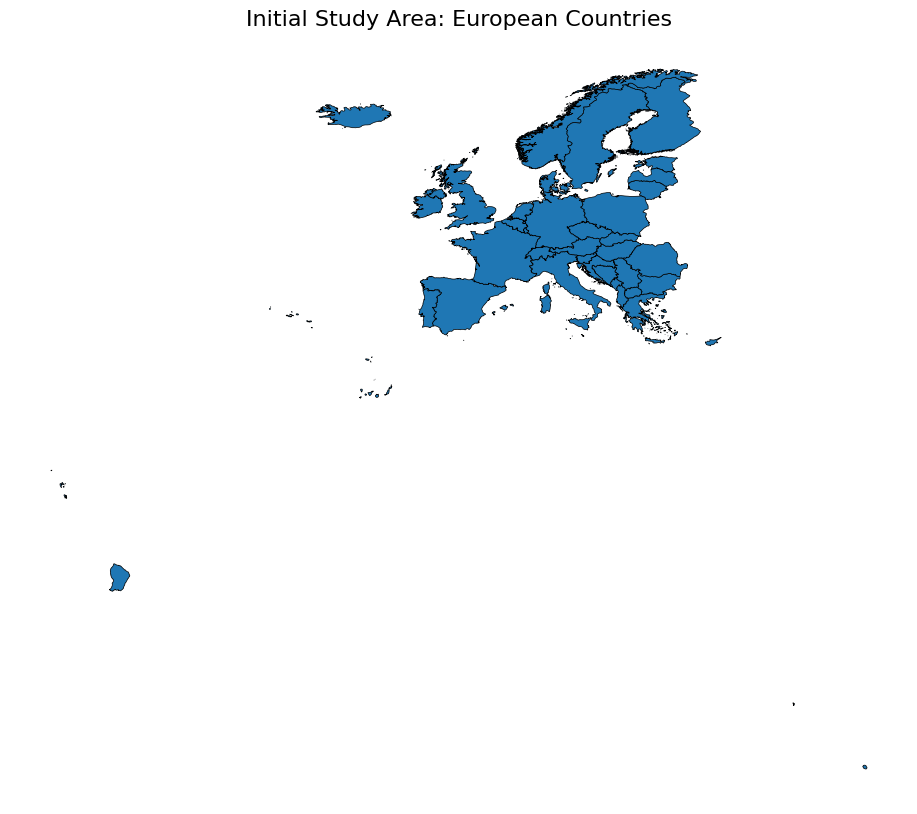

In [ ]:
fig, ax = plt.subplots(figsize=(14, 10))
europe.plot(ax=ax, edgecolor="black", linewidth=0.5)
ax.set_title("Initial Study Area: European Countries", fontsize=16)
ax.set_axis_off()
plt.show()

## 5. Завантаження даних ВВП з Eurostat

Завантажуємо річний реальний ВВП (`nama_10_gdp`, `CLV10_MEUR`, `B1GQ`) для всіх країн початкової території за 2012–2025 роки. Eurostat відхиляє весь запит, якщо в ньому є код країни, якої немає в наборі даних (наприклад, `LI`, а після оновлення набору — і `UK`). Тому спершу визначаємо, які коди доступні, і запитуємо лише їх.

In [ ]:
gdp = download_gdp(sorted(europe["CNTR_ID"]), YEARS)

print("GDP shape:", gdp.shape)
gdp.head()

Not available in Eurostat dataset: ['UK']
GDP shape: (35, 15)


,geo,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AL,9433.6,9594.6,9809.6,10028.1,10420.1,10762.2,11157.3,11387.4,11010.1,11997.6,12576.7,13081.7,13611.0,NaN
1,AT,304560.3,303796.7,306092.8,310082.8,316647.9,323842.9,331887.9,337712.4,316374.9,331950.3,350052.2,347671.8,346673.0,348985.5
2,BA,12985.7,13290.9,13444.2,14020.2,14474.8,14944.3,15516.6,15964.3,15483.0,16627.5,17330.3,17675.9,18246.3,18689.5
3,BE,371056.2,372189.8,378760.9,384344.5,388931.6,394666.3,402078.0,411900.3,392158.0,416685.4,433472.6,440318.7,444271.0,448440.2
4,BG,39382.4,39168.7,39540.6,40884.0,42121.4,43278.0,44403.7,45847.5,44715.6,47432.1,48989.5,49968.3,51616.3,53173.3


## 6. Кінцева територія дослідження

**Критерій включення:** до кінцевої вибірки потрапляють лише країни, для яких кількість років без даних ВВП за період дослідження не перевищує `MAX_MISSING_GDP` (2 роки).

Країни, яких немає в наборі даних Eurostat, автоматично отримують пропуски за всі роки і виключаються.

In [ ]:
availability = gdp_availability(europe, gdp, YEARS, MAX_MISSING_GDP)

print(f"Countries before GDP filter: {len(availability)}")
print(f"Countries retained: {availability['include'].sum()}")
print(f"Countries excluded: {(~availability['include']).sum()}")

# Countries excluded or with incomplete GDP series
availability.loc[~availability["complete_period"]]

Countries before GDP filter: 37
Countries retained: 35
Countries excluded: 2


,CNTR_ID,NAME_ENGL,n_years_available,n_missing_gdp,missing_years,complete_period,include
0,LI,Liechtenstein,0,14,"[2012, 2013, 2014, 2015, 2016, 2017, 2018, 201...",False,False
1,UK,United Kingdom,0,14,"[2012, 2013, 2014, 2015, 2016, 2017, 2018, 201...",False,False
2,AL,Albania,13,1,[2025],False,True


In [ ]:
included_codes = availability.loc[availability["include"], "CNTR_ID"]
study_area = europe.loc[europe["CNTR_ID"].isin(included_codes)].copy()

print(f"Final study area: {len(study_area)} countries")

Final study area: 35 countries


## 7. Збереження результатів

Зберігаємо ряди ВВП, таблицю наявності даних та межі кінцевої території дослідження — їх використовуватимуть наступні ноутбуки.

In [ ]:
gdp.to_csv(GDP_PATH, index=False)
availability.to_csv(GDP_AVAILABILITY_PATH, index=False)
study_area.to_file(STUDY_AREA_PATH, driver="GeoJSON")

for path in (GDP_PATH, GDP_AVAILABILITY_PATH, STUDY_AREA_PATH):
    print("Saved:", path)

Saved: /content/drive/MyDrive/GDP_NTL_Project/data/economic/eurostat_nama_10_gdp_2012_2025.csv
Saved: /content/drive/MyDrive/GDP_NTL_Project/data/metadata/gdp_availability_2012_2025.csv
Saved: /content/drive/MyDrive/GDP_NTL_Project/data/metadata/study_area.geojson
